---
title: ""
lang: uk
format:
  typst:
    mainfont: "Times New Roman"
    fontsize: 14pt
    margin: { x: 2.5cm, y: 2.5cm }
  docx: default
  pdf:
    pdf-engine: lualatex
    mainfont: "Times New Roman"
---

```{=typst}
// Configure the page.
#set page(
  paper: "a4",
  // The margins depend on the paper size.
  margin: (x: 2cm, y: 1.5cm),
  numbering:  (current, total) => if current > 1 { current }, number-align: right, 
)

// Configure styling
#set par(
  leading: 0.8em,
  spacing: 1em,
  justify: true,
)
#show table: set text(size: 9pt)

#align(top + center)[
  Міністерство освіти і науки України \
  Національний університет «Львівська політехніка» \
  Кафедра систем штучного інтелекту \
  \
  #image("logo.png", width: 6cm)
  \
  #set par(spacing: 0.4em)
  #text(size: 24pt, weight: "bold")[Звіт]
  #set par(spacing: 0.8em)

  *про виконання лабораторної роботи № 4* \
  _з дисципліни:_ «Обробка мови методами штучного інтелекту»
]

#align(bottom + right)[
  Виконав: \
  студент групи ШІ-42 \
  Горишевський Олексій Олександрович
]

#pagebreak()
```

# Spellchecker quest

Хтось наробив помилок у віршах Тараса Шевченка. Ваша задача -- виправити ці помилки і прочитати приховане повідомлення.

## Задача

Ви отримаєте тренувальні та тестувальні дані.

Тренувальні дані знаходяться в полі `lab.train_text`. Це звичайний нерозмічений текст. На ньому необхідно натренувати мовну модель. Підійде будь-яка: n-грамна, feed-forward нейронну модель або їх ансамбль. Токенізацію раджу робити по літерах або BPE.

Тестувальні дані знаходиться в полі `lab.test_items`. Приклад одного елемента:

```json
{
  "text": "Співали б прозу, та по ножах,",
  "error_start": 23,
  "error_end": 28,
  "error": "ножах",
  "corrections": [
    "ногах",
    "йотах",
    "єнотах",
    "ножах",
    "нотах"
  ]
}
```

`error_start` та `error_end` вказують на місцезнаходження помилки в тексті (в символах). У цьому прикладі помилкою є `text[23:28]`, тобто слово "ножах".

`corrections` -- це список можливих виправлень.

Ваша задача -- натренувати мовну модель та за її допомогою обрати правильне виправлення серед запропонованих.


## Приховане повідомлення

Один приклад в `lab.test_items` дає можливість прочитати одну літеру прихованого повідомлення. Для цього знайдіть різницю між літерами слова з помилкою (`error`) та обраним моделлю виправленням. Надрукуйте цю літеру. Якщо слово з помилкою насправді правильне, а таке теж буває, надрукуйте пробіл. Приклади:

```
Error               Correction     Надрукувати
-------------------------------------------
привіт               приліт        л
пні                  поні          о
баллет               балет         л
привіт               привіт        [пробіл]
```

Приховане повідомлення, яке ви побачите в результаті -- це рядок з віршу одного з українських авторів.

Відповідь на квест -- ім'я автора/ки у форматі "Ім'я Прізвище".

Полетіли! 🚀

In [123]:
%pip install --quiet --upgrade https://static.lp-nlp.com/pypi/lpnlp-2026.10.1-py3-none-any.whl

Note: you may need to restart the kernel to use updated packages.


In [124]:
import lpnlp

lab = lpnlp.start(
    email="oleksii.ivanov.shi.2023@lpnu.ua",
    lab="quest_spellchecker"
)

Удачі!


In [125]:
# Якщо вам потрібні тренувальні дані у вигляді файлу на вашому комп'ютері,
# розкоментуйте цей код:

# with open("train.txt", "wt") as f:
#     f.write(lab.train_text)

# from google.colab import files
# files.download("train.txt")

## Мовна модель

Натренуйте свою мовну модель тут

In [126]:
print(lab.train_text[:330])

ПРИЧИННА

Реве та стогне Дніпр широкий,
Сердитий вітер завива,
Додолу верби гне високі,
Горами хвилю підійма.
І блідий місяць на ту пору
Із хмари де-де виглядав,
Неначе човен в синім морі,
То виринав, то потопав.
Ще треті півні не співали,
Ніхто нігде не гомонів,
Сичі в гаю перекликались,
Та ясен раз у раз скрипів.
В таку добу п


In [127]:
%pip install --quiet tqdm matplotlib

Note: you may need to restart the kernel to use updated packages.


In [128]:
from collections import Counter

NGRAM_ORDER = 4
PAD = "\n"

def ngram(order, d, corpus):
    context_size = order - 1
    text = PAD * context_size + corpus
    vocab = set(text)

    model = Counter()           # (context, char) -> count
    context_counts = Counter()  # context -> count
    followers = Counter()       # context -> how many DIFFERENT chars followed it

    for i in range(context_size, len(text)):
        target = text[i]
        for k in range(context_size + 1):
            context = text[i - k:i]
            if model[(context, target)] == 0:    # first time we see this pair
                followers[context] += 1
            model[(context, target)] += 1
            context_counts[context] += 1

    return model, context_size, context_counts, followers, vocab, d

In [129]:
import math

def char_prob(ngram, context, target):
    model, context_size, context_counts, followers, vocab, d = ngram
    
    p = 1 / (len(vocab) + 1)                    # level 0: uniform guess
    for k in range(context_size + 1):        # context length 0, 1, ..., 5
        h = context[context_size - k:]       # last k characters
        total = context_counts[h]
        if total == 0:                       # context never seen: skip this level
            continue
        count = model[(h, target)]
        p = max(count - d, 0) / total + d * followers[h] / total * p

    return p

def char_nll(ngram, context, target):
    return -math.log(char_prob(ngram, context, target))

def text_nll(ngram, s):
    context_size = ngram[1]
    padded = PAD * context_size + s
    return sum(
        char_nll(ngram, padded[i - context_size:i], padded[i])
        for i in range(context_size, len(padded))
    )

# Читаємо між рядків

In [142]:
import collections
from typing import List, Tuple


# Допоміжна функція:
def get_letter(error: str, correction: str) -> str:
    """Повертає літеру повідомлення або пробіл для незміненого слова."""
    error = error.lower()
    correction = correction.lower()

    if error == correction:
        return " "

    added = collections.Counter(correction) - collections.Counter(error)
    removed = collections.Counter(error) - collections.Counter(correction)
    difference = added or removed

    if sum(difference.values()) != 1:
        raise ValueError(
            f"Очікувалася різниця в одну літеру: {error!r} → {correction!r}"
        )

    return next(iter(difference))


assert get_letter("привіт", "приліт") == "л"
assert get_letter("пні", "поні") == "о"
assert get_letter("баллет", "балет") == "л"
assert get_letter("Привіт", "привіт") == " "


def score_candidate_ngram(ngram, item, correction):
    context_size = ngram[1]
    line = (
        item["text"][: item["error_start"]]
        + correction
        + item["text"][item["error_end"] :]
    )
    padded = PAD * context_size + line + "\n"

    total_nll = 0.0
    for pos in range(context_size, len(padded)):
        total_nll += char_nll(ngram, padded[pos - context_size : pos], padded[pos])
    return total_nll


def edit_distance(s1: str, s2: str) -> int:
    """Обчислює відстань Левенштейна між двома рядками."""
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if s1[i - 1] == s2[j - 1] else 1
            dp[i][j] = min(
                dp[i - 1][j] + 1,  # видалення
                dp[i][j - 1] + 1,  # вставка
                dp[i - 1][j - 1] + cost,  # заміна
            )

    return dp[m][n]


# Можете змінювати параметри та весь цей код, якщо потрібно
def solve(ngram, test_items) -> Tuple[List[str], str]:
    """Повертає список виправлених слів для кожного з текстів в test_items та
    секретне повідомлення.
    """

    choices = []
    secret = []

    for item in test_items:
        # Обираємо найкращу заміну
        valid_corrections = [
            correction
            for correction in item["corrections"]
            if edit_distance(item["error"], correction) <= 1
        ]
        best_word = min(
            valid_corrections,
            key=lambda corr: score_candidate_ngram(ngram, item, corr),
        )
        choices.append(best_word)

        # Знаходимо чергову літеру повідомлення
        error = item["error"]
        letter = get_letter(error, best_word)
        secret.append(letter)

    secret_message = "".join(secret)

    return choices, secret_message


for order in range(4, 9):
    for d in [0.6, 0.7, 0.8, 0.9]:
        print(f"order={order}, d={d}")
        n_gram = ngram(order, d, lab.train_text)
        choices, secret_message = solve(n_gram, lab.test_items)
        lab.evaluate_accuracy(choices)
        print("SECRET MESSAGE: ", secret_message)

order=4, d=0.6
Відповідь правильна ✅
accuracy = 0.82. Непогано! Спробуй розгадай приховане повідомлення
SECRET MESSAGE:  гетьте думи вию ма  иос нвідт  ввтепера  еснаизоло а  и  о так у жіл  вкг лосінні промибуть долоді  л та ні я хочу крізь сльози см яти ь серед л ха с а  ти  існімгезтнадії таки сподіва ись жити хочу геть  у и сумні
order=4, d=0.7
Відповідь правильна ✅
accuracy = 0.81. Непогано! Спробуй розгадай приховане повідомлення
SECRET MESSAGE:  гетьте думи вию ма  иос нвідт  вв епера  еснаизоло а  и  о так у жіл  вкг лосінні промибуть долоді сл та ні я хочу крізь сльози см яти ь серед л ха с а  ти  існімгезтнадії таки сподіва ись жити хочу геть  у и сумні
order=4, d=0.8
Відповідь правильна ✅
accuracy = 0.81. Непогано! Спробуй розгадай приховане повідомлення
SECRET MESSAGE:  гетьте думипвию ма  иос нвідт  вв епера  еснаизоло а  и  о так у жіл  вкг лосінні промибуть долоді сл та ні я хочу крізь сльози см яти ь серед л ха с а  ти  існімгезтнадії таки сподіва ись жити хочу геть  у 

In [138]:
lab.answer("Леся Українка")

Відповідь правильна ✅
Правильно! 🚀 Заповни тепер цю форму, будь ласка: https://tally.so/r/wkl0zZ


# Perplexity

Окрім точності виправлення помилок, оцінимо, наскільки добре ваша модель передбачає текст, якого вона не бачила під час навчання.
Для цього в пакеті є файл `valid.txt`. Його вміст доступний через `lab.valid_text`. Цей текст не входить до тренувальних даних.

Не тренуйте модель або токенізатор на `lab.valid_text`! Використовуйте його лише для оцінювання.

### Що порахувати

Токенізуйте `lab.valid_text` тим самим токенізатором, що й тренувальні дані. Для кожного токена знайдіть імовірність, яку модель надає йому з урахуванням попереднього контексту.

Порахуйте:

1. `N_tokens` — кількість текстових токенів, для яких обчислено ймовірність.
2. `total_NLL` — сумарний від’ємний логарифм їхніх імовірностей:

   ```text
   total_NLL = -Σ ln p(token_i | попередній контекст)
   ```

3. Perplexity на токен:

   ```python
   perplexity = math.exp(total_NLL / N_tokens)
   ```

Менша perplexity означає, що модель краще передбачає цей текст.

Perplexity на токен залежить від токенізації. Наприклад, не можна напряму порівнювати perplexity моделі на літерах із perplexity моделі на BPE-токенах.

Тому додатково порахуйте

4. Perplexity на символ:

```python
N_chars = len(lab.valid_text)
character_perplexity = math.exp(total_NLL / N_chars)
```

У `N_chars` враховуйте весь початковий текст, включно з пробілами та символами нового рядка. Для обох метрик використовуйте той самий `total_NLL`.

Для коректного порівняння моделі мають оцінювати той самий текст. Якщо ви замінюєте невідомі слова на `<unk>`, переводите текст у нижній регістр або викидаєте розділові знаки, ви оцінюєте змінений текст — обов’язково зазначте це у звіті.


In [136]:
n_valid = len(lab.valid_text)
results = []
for order in range(3, 10):
    for d in [0.6, 0.7, 0.8, 0.9, 0.95]:
        model = ngram(order, d, lab.train_text)
        perplexity = math.exp(text_nll(model, lab.valid_text) / n_valid)
        results.append((perplexity, order, d))

best_perplexity, best_order, best_d = min(results)
best = ngram(best_order, best_d, lab.train_text)
print(f"\nBest model: order={best_order}, d={best_d}, perplexity={best_perplexity:.3f}")

choices, secret_message = solve(best, lab.test_items)
lab.evaluate_accuracy(choices)
print("SECRET MESSAGE: ", secret_message)


Best model: order=5, d=0.9, perplexity=5.972
Відповідь правильна ✅
accuracy = 0.84. Непогано! Спробуй розгадай приховане повідомлення
SECRET MESSAGE:  гетьте думи ви  м р иос н ід о вв епера  есна золо а чи  о так у жалю вкголодінн  промибуть долоді  л та ні я хочу крізь с ьози см яти ь серед л хапс і  ти піснігбезтнадіїйтаки сподіва ись жити хочу геть вуми сумні


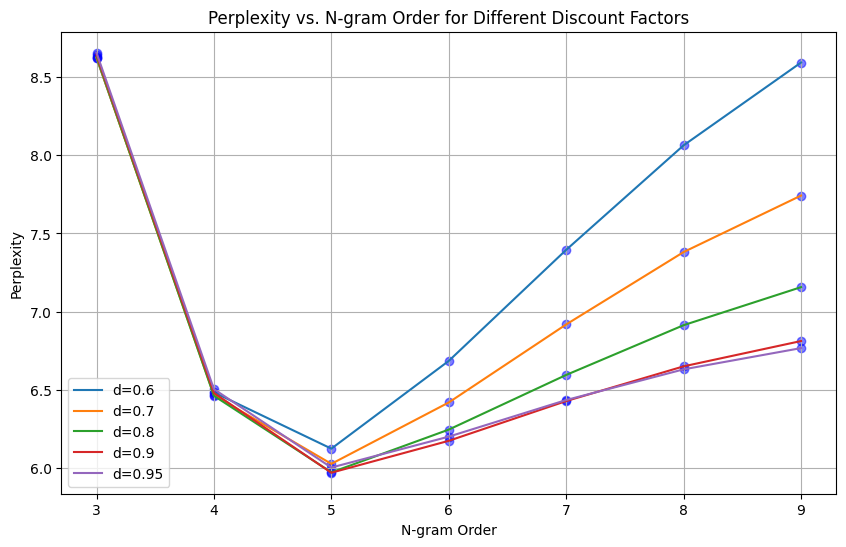

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# scatter plot for all results
for perplexity, order, d in results:
    plt.scatter(order, perplexity, color="blue", alpha=0.5)

# line plot for each d
for d in [0.6, 0.7, 0.8, 0.9, 0.95]:
    d_results = [(order, ppl) for ppl, order, d_ in results if d_ == d]
    d_results.sort()
    orders, perplexities = zip(*d_results)
    plt.plot(orders, perplexities, label=f"d={d}")

plt.title("Perplexity vs. N-gram Order for Different Discount Factors")
plt.xlabel("N-gram Order")
plt.ylabel("Perplexity")
plt.xticks(range(3, 10))
plt.legend()
plt.grid()
plt.show()

In [ ]:
report = {
    "model_and_context": f"Символьна {best_order}-грамна, інтерпольоване абсолютне дисконтування (D={best_d}), контекст {best_order-1} символів",
    "tokenization_and_vocab": f"Літери, {len(best[4])} символів у словнику (+1 для невідомих)",
    "n_chars": len(lab.valid_text),
    "n_tokens": len(lab.valid_text),
    "total_nll": text_nll(best, lab.valid_text),
    "token_perplexity": math.exp(text_nll(best, lab.valid_text) / len(lab.valid_text)),
    "character_perplexity": math.exp(text_nll(best, lab.valid_text) / len(lab.valid_text)),

    # Опишіть зміну регістру, обробку невідомих токенів, пробілів і пунктуації,
    # використання BOS/EOS, поділ на вікна та обробку їхніх меж.
    "processing_notes": "",
}
report

{'model_and_context': 'Символьна 5-грамна, інтерпольоване абсолютне дисконтування (D=0.9), контекст 4 символів',
 'tokenization_and_vocab': 'Літери, 118 символів у словнику (+1 для невідомих)',
 'n_chars': 10172,
 'n_tokens': 10172,
 'total_nll': 18177.51098336253,
 'token_perplexity': 5.971597322349492,
 'character_perplexity': 5.971597322349492,
 'processing_notes': ''}

📝  Відправте посилання на цей colab або PDF з ним у відповідне завдання VNS або на email викладачу, що приймає лабораторні
